# How does an animal know where it is in space?

To know where it is, an animal needs at least two internal signals: which way it is facing, and where it
is relative to the environment. In the rodent medial entorhinal cortex (MEC) both signals appear in the
firing of single neurons:

- **Head-direction (HD) cells** fire when the head points in one direction, wherever the animal is.
- **Grid cells** fire at several locations that form a triangular (hexagonal) lattice across the floor.
- **Conjunctive grid x HD cells** fire at grid locations, but only when the animal faces one direction.

Together these cells can support path integration: heading and running speed are combined to update a
position estimate as the animal moves.

This notebook tests these ideas on real recordings from **DANDI:000582**
([Sargolini et al., Science 2006](https://doi.org/10.1126/science.1125572)): tetrode recordings from MEC
layers II, III, V and VI of rats foraging for food in open arenas, with two head-mounted LEDs giving
position and heading. The steps are:

1. Look at raw behaviour and spikes from one session.
2. Compute rate maps, spatial autocorrelograms (gridness) and head-direction tuning for every unit in
   all 118 sessions, with time-shift shuffles as a null distribution.
3. Classify cells and compare layers.
4. Decode the animal's heading and position from population activity on held-out data.

Shared code lives in `spatial_lib.py`. The per-session workers come from `03_analyze_all_sessions.py`
and `04_decode_position_heading.py`, and the summary figures from `05_visualize.py`.

In [1]:
import importlib.util
import os
import sys
from multiprocessing import Pool

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from tqdm import tqdm

from spatial_lib import (autocorr2d, gridness, hd_curves, list_sessions, load_session, mean_vector, rate_maps,
                         spatial_info)

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)


def load_module(path):
    spec = importlib.util.spec_from_file_location(os.path.basename(path)[:-3].lstrip("0123456789_"), path)
    mod = importlib.util.module_from_spec(spec)
    sys.modules[spec.name] = mod  # so worker processes can pickle its functions
    spec.loader.exec_module(mod)
    return mod

## 1. One session: raw data

Files are streamed from the DANDI S3 bucket with `remfile` and a local disk cache. Position is the
midpoint of the two LEDs and head direction is the angle of the LED1 to LED2 vector. Only periods when
the rat runs faster than 2.5 cm/s are used for tuning.

Because the LED order relative to the nose is not documented, head direction is defined up to a
constant offset. This affects preferred directions, not tuning strength.

In [2]:
sessions = list_sessions()
print(f"{len(sessions)} NWB files in DANDI:000582")
PATH = "sub-11265/sub-11265_ses-01020602_behavior+ecephys.nwb"
units, position, head_dir, moving, meta = load_session(dict(sessions)[PATH])
print(meta)
print(units)
print(position)

118 NWB files in DANDI:000582


{'session_id': '01020602', 'subject_id': '11265', 'duration': np.float64(599.8399999999992), 'fs': np.float64(49.999999998908606), 'arena': [(np.float64(-49.99610137772301), np.float64(50.00389862227699)), (np.float64(-50.02722588079932), np.float64(49.97277411920068))], 'box_side': np.float64(100.0)}
  Index     rate  unit_name    histology
-------  -------  -----------  -----------
      0  2.47175  t1c2         MEC LIII
      1  4.79017  t1c4         MEC LIII
      2  0.38835  t2c1         MEC LIII
      3  1.48838  t3c2         MEC LIII
      4  1.71839  t4c1         MEC LIII
      5  1.41338  t4c4         MEC LIII
      6  1.26838  t7c1         MEC LIII
      7  1.57672  t8c1         MEC LIII
      8  1.8834   t8c2         MEC LIII
Time (s)                    x        y
-------------------  --------  -------
0.14000000000032742  -48.4641  37.086
0.15999999999985448  -48.3218  36.4779
0.18000000000029104  -48.2135  35.865
0.1999999999998181   -48.205   35.2112
0.22000000000025466  

/usr/local/lib/python3.13/dist-packages/pynapple/core/ts_group.py:318: FutureWarning: initializing metadata with variable keyword arguments may be unsupported in a future version of Pynapple. Instead, initialize using the metadata argument.
  warnings.warn(


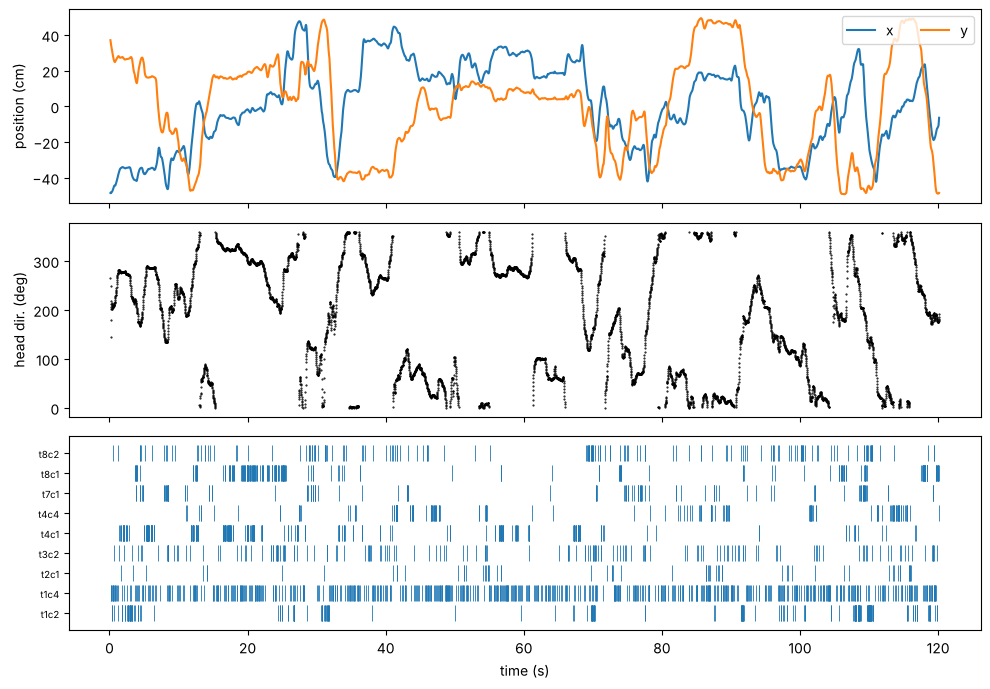

In [3]:
win = position.time_support.start[0] + np.array([0, 120])
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
p = position.get(*win)
axes[0].plot(p.t, p["x"], label="x")
axes[0].plot(p.t, p["y"], label="y")
axes[0].set_ylabel("position (cm)")
axes[0].legend(loc="upper right", ncol=2)
h = head_dir.get(*win)
axes[1].plot(h.t, np.degrees(h.values), ".", ms=1, color="k")
axes[1].set_ylabel("head dir. (deg)")
for k, u in enumerate(units.index):
    axes[2].vlines(units[u].get(*win).t, k + 0.6, k + 1.4, lw=0.6)
axes[2].set_yticks(range(1, len(units) + 1), units.metadata["unit_name"].values, fontsize=7)
axes[2].set_xlabel("time (s)")
fig.tight_layout()
plt.show()

## 2. One session: what does each neuron encode?

For each unit we compute:

- a **rate map** (2.5 cm bins, Gaussian-smoothed) with `pynapple.compute_tuning_curves`;
- its **spatial autocorrelogram** and **gridness score**: the correlation of the autocorrelogram with
  itself rotated by 60 and 120 degrees minus the correlation at 30, 90 and 150 degrees. A hexagonal
  lattice gives a high score;
- a **head-direction tuning curve** (6 degree bins) and its **mean vector length (MVL)**, which is 0 for
  untuned cells and 1 for perfectly tuned cells.

In [4]:
maps, occ = rate_maps(units, position, moving, meta["arena"])
curves, centers = hd_curves(units, head_dir, moving)
mvl, pref = mean_vector(curves, centers)
si = spatial_info(maps, occ)
acs = [autocorr2d(m) for m in maps]
gs = [gridness(a) for a in acs]
pd.DataFrame(dict(unit=units.metadata["unit_name"].values, spatial_info=si, gridness=gs, mvl=mvl)).round(2)

,unit,spatial_info,gridness,mvl
0,t1c2,0.87,1.14,0.61
1,t1c4,0.04,-0.05,0.09
2,t2c1,0.81,-0.18,0.63
3,t3c2,0.16,0.29,0.24
4,t4c1,0.76,-0.05,0.83
5,t4c4,1.17,0.90,0.79
6,t7c1,0.69,0.76,0.53
7,t8c1,1.63,1.16,0.68
8,t8c2,0.19,0.02,0.45


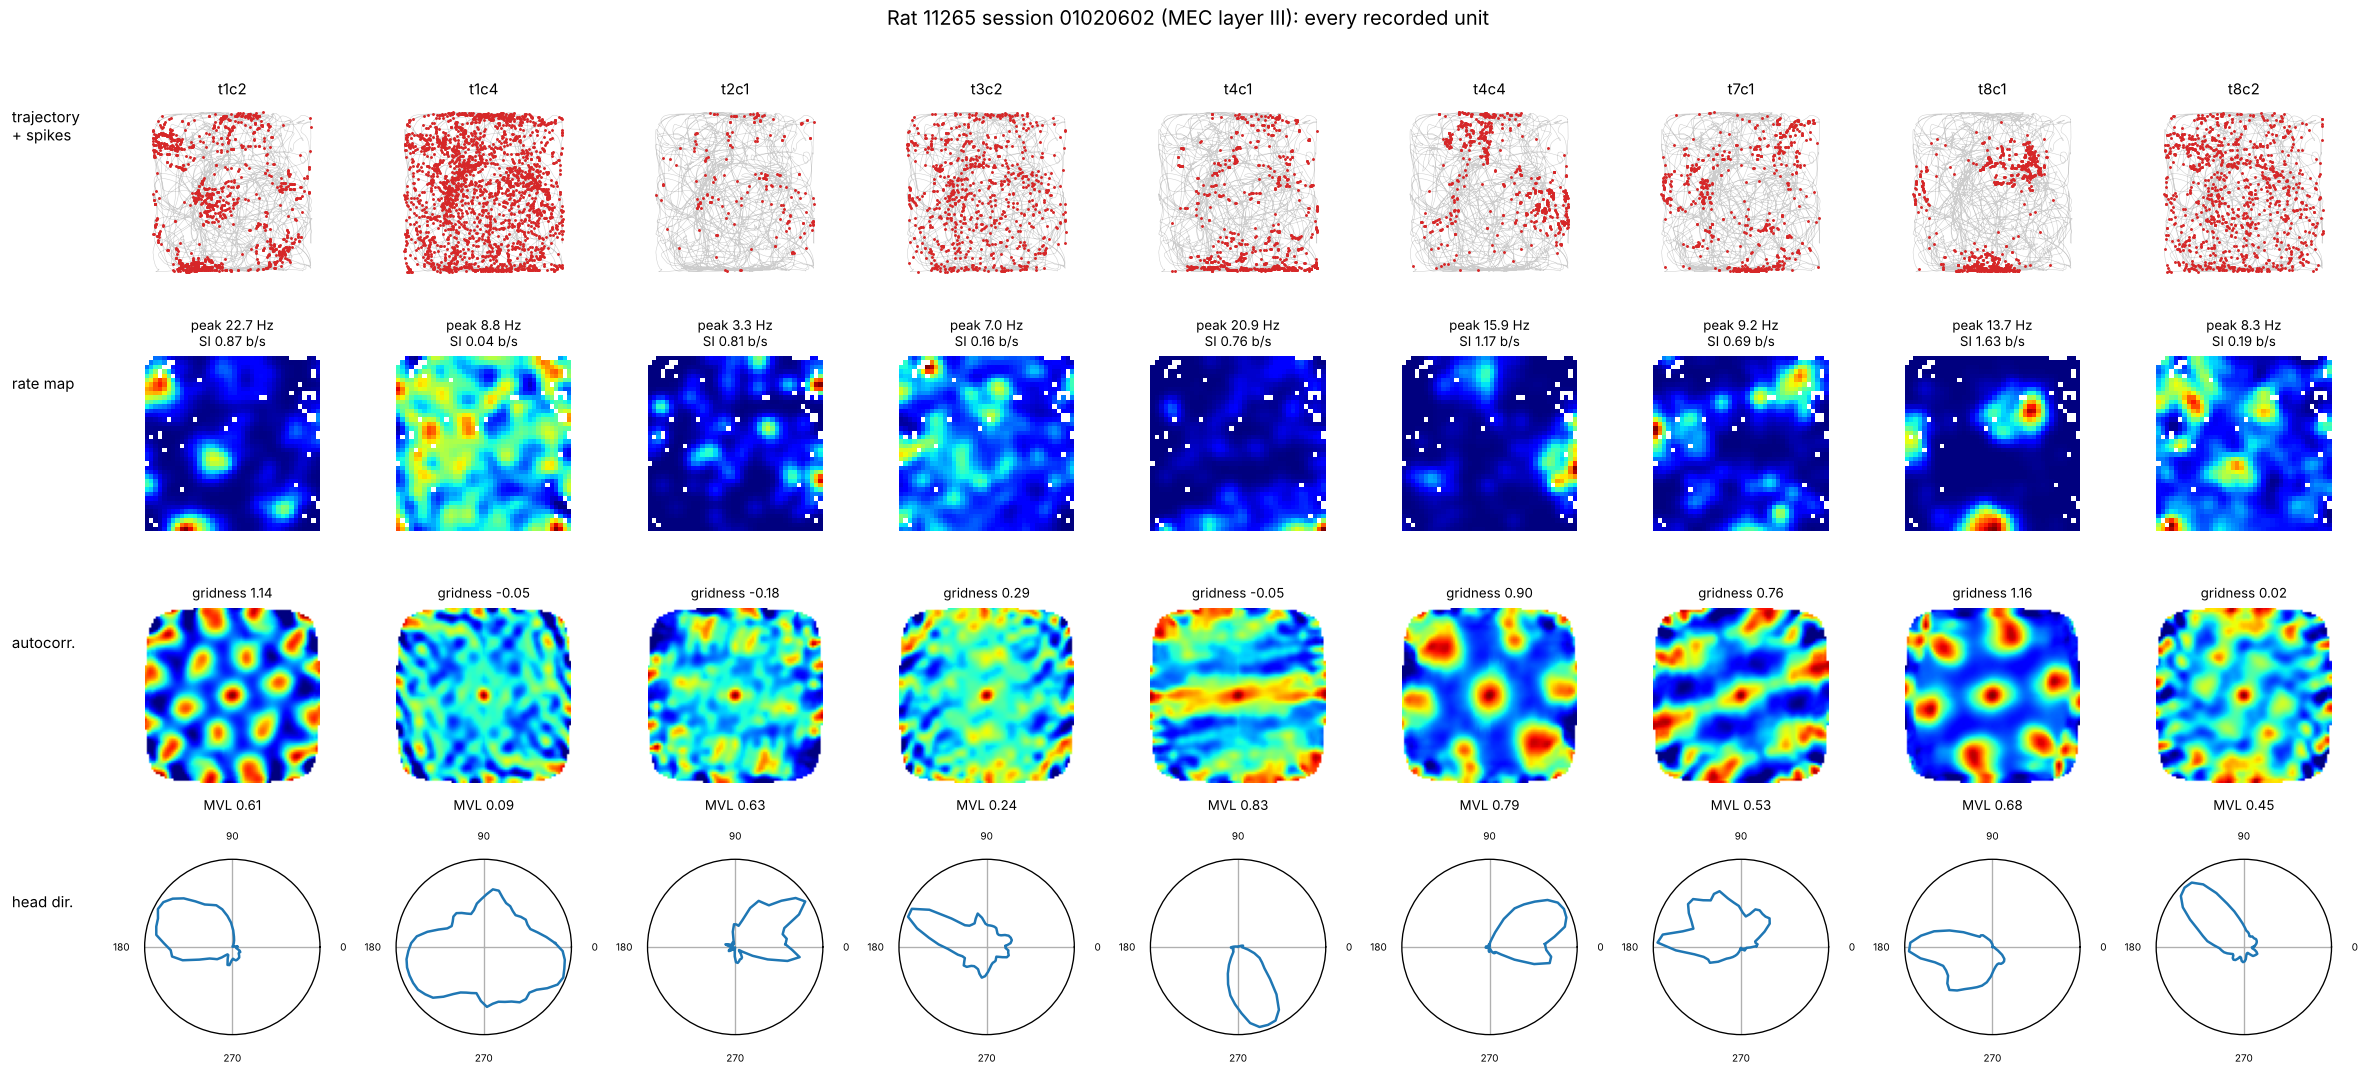

In [5]:
display(Image("figures/02_single_session_units.png"))

Several units in this layer III session (t1c2, t4c4, t8c1) have a clear hexagonal autocorrelogram, and
most of these grid cells are also tuned to head direction. They are conjunctive cells. Other units
(t2c1, t4c1) are tuned to heading but have no grid structure.

## 3. All sessions

The same metrics are computed for every unit in all 118 sessions. For a null distribution, each spike
train is circularly shifted in time by at least 20 s (100 shuffles per unit). This keeps the spike
train's structure but removes its relation to behaviour. A unit counts as a grid cell or HD cell if its
score exceeds the 99th percentile of the pooled shuffle distribution, as in Sargolini et al. (2006).

Although every file's `session_description` says "1 x 1 meter enclosure", the tracking data in 22
sessions span about 1.5 m or 2 m. The 2 m sessions have almost no occupancy in the corners, which
suggests a circular arena. The arena size is therefore inferred per session from the tracking extent.

This step takes about 10 minutes on 4 cores.

In [6]:
analysis = load_module("03_analyze_all_sessions.py")
rows, all_maps, all_acs, all_curves, shuf = [], [], [], [], []
with Pool(os.cpu_count()) as pool:
    for r, m, a, c, s in tqdm(pool.imap(analysis.analyze, sessions), total=len(sessions)):
        rows += r
        all_maps += list(m)
        all_acs += list(a)
        all_curves += list(c)
        shuf += s
df = pd.DataFrame(rows)
df.to_csv("results/units.csv", index=False)
obj = lambda x: np.array(x + [None], dtype=object)[:-1]
np.savez_compressed("results/maps.npz", maps=obj(all_maps), acs=obj(all_acs), curves=np.array(all_curves),
                    shuffles=np.array(shuf))
print(f"{len(df)} units from {df.path.nunique()} sessions and {df.subject.nunique()} rats")
df.groupby("layer").size()

  0%|          | 0/118 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/pynapple/core/ts_group.py:318: FutureWarning: initializing metadata with variable keyword arguments may be unsupported in a future version of Pynapple. Instead, initialize using the metadata argument.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/pynapple/core/ts_group.py:318: FutureWarning: initializing metadata with variable keyword arguments may be unsupported in a future version of Pynapple. Instead, initialize using the metadata argument.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/pynapple/core/ts_group.py:318: FutureWarning: initializing metadata with variable keyword arguments may be unsupported in a future version of Pynapple. Instead, initialize using the metadata argument.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/pynapple/core/ts_group.py:318: FutureWarning: initializing metadata with variable keyword arguments may be unsupported in a future version of Pynapple. Instead, initialize using the metadata argument.
  warnings.warn(


...

 94%|█████████▍| 111/118 [06:58<00:50,  7.22s/it]

 97%|█████████▋| 114/118 [07:03<00:19,  4.81s/it]

100%|██████████| 118/118 [07:03<00:00,  3.59s/it]

620 units from 118 sessions and 15 rats


layer
              6
MEC LII      71
MEC LIII    227
MEC LV      118
MEC LVI     198
dtype: int64

## 4. Population decoding

If these cells tell the animal where it is and which way it faces, then the animal's heading and
position should be readable from their spikes. For every session with at least 5 units, a Bayesian
decoder (`pynapple.decode_bayes`, 1 s windows) is fit on even minutes and tested on odd minutes, and
vice versa. Chance is the error obtained when decoding time-shifted spike trains with the same model.

In [7]:
decoding = load_module("04_decode_position_heading.py")
with Pool(os.cpu_count()) as pool:
    res = [r for r in tqdm(pool.imap(decoding.run, sessions), total=len(sessions)) if r is not None]
dec = pd.DataFrame([r[0] for r in res])
dec.to_csv("results/decoding.csv", index=False)
best = dec[dec.hd_err.notna()].sort_values("n_units", ascending=False).index[0]
np.savez("results/decoding_example.npz", path=dec.loc[best, "path"],
         **{f"{k}_{f}_{i}": v for k, folds_ in res[best][1].items() for f, fold in enumerate(folds_)
            for i, v in zip(("t", "dec", "true"), fold)})
dec.round(1)

  0%|          | 0/118 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/pynapple/core/ts_group.py:318: FutureWarning: initializing metadata with variable keyword arguments may be unsupported in a future version of Pynapple. Instead, initialize using the metadata argument.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/pynapple/core/ts_group.py:318: FutureWarning: initializing metadata with variable keyword arguments may be unsupported in a future version of Pynapple. Instead, initialize using the metadata argument.
  warnings.warn(


/home/user/dandi-showcase-runs/spatial_a/04_decode_position_heading.py:29: UserWarning: Some starts and ends are equal. Removing 1 microsecond!
  minutes = nap.IntervalSet(edges[:-1], edges[1:])


/usr/local/lib/python3.13/dist-packages/pynapple/core/ts_group.py:318: FutureWarning: initializing metadata with variable keyword arguments may be unsupported in a future version of Pynapple. Instead, initialize using the metadata argument.
  warnings.warn(


...

/usr/local/lib/python3.13/dist-packages/pynapple/process/decoding.py:398: RuntimeWarning: divide by zero encountered in log
  log_posterior = log_likelihood + np.log(prior)


/home/user/dandi-showcase-runs/spatial_a/04_decode_position_heading.py:29: UserWarning: Some starts and ends are equal. Removing 1 microsecond!
  minutes = nap.IntervalSet(edges[:-1], edges[1:])


 94%|█████████▍| 111/118 [00:53<00:07,  1.02s/it]

100%|██████████| 118/118 [00:53<00:00,  2.19it/s]

,path,subject,session,n_units,box_cm,pos_err,pos_chance,pos_chance_p05,hd_err,hd_chance,hd_chance_p05
0,sub-10073/sub-10073_ses-17010302_behavior+ecep...,10073,17010302,8,100.0,43.4,52.9,49.4,NaN,NaN,NaN
1,sub-10697/sub-10697_ses-02030402_behavior+ecep...,10697,02030402,5,100.0,42.8,50.4,47.0,NaN,NaN,NaN
2,sub-10697/sub-10697_ses-24020402_behavior+ecep...,10697,24020402,5,100.0,40.8,50.2,49.3,NaN,NaN,NaN
3,sub-10704/sub-10704_ses-07070407_behavior+ecep...,10704,07070407,6,100.0,44.9,48.1,46.6,NaN,NaN,NaN
4,sub-10704/sub-10704_ses-08070402_behavior+ecep...,10704,08070402,7,100.0,45.9,53.6,49.4,NaN,NaN,NaN
5,sub-10704/sub-10704_ses-20060402_behavior+ecep...,10704,20060402,9,100.0,40.6,48.5,44.8,NaN,NaN,NaN
6,sub-10704/sub-10704_ses-26060402_behavior+ecep...,10704,26060402,5,100.0,40.9,49.1,44.4,NaN,NaN,NaN
7,sub-10884/sub-10884_ses-03080402_behavior+ecep...,10884,03080402,6,100.0,49.2,51.3,46.2,NaN,NaN,NaN
8,sub-10962/sub-10962_ses-27110403_behavior+ecep...,10962,27110403,5,100.0,47.4,51.3,46.4,NaN,NaN,NaN
9,sub-11016/sub-11016_ses-31010502_behavior+ecep...,11016,31010502,5,100.0,45.8,50.8,46.8,NaN,NaN,NaN


## 5. Results

In [8]:
%run 05_visualize.py

thresholds: {'spatial_info': np.float64(1.181), 'gridness': np.float64(0.839), 'mvl': np.float64(0.27)}
cls       conjunctive grid x HD  grid (no HD data)  not classified  \
layer                                                                
MEC LII                       0                 10              38   
MEC LIII                     36                  5              92   
MEC LV                        6                  6              41   
MEC LVI                       3                 15              70   
unknown                       0                  0               0   

cls       other spatial  pure grid  pure head direction  total  
layer                                                           
MEC LII              12          9                    2     71  
MEC LIII             14         30                   50    227  
MEC LV                0          1                   64    118  
MEC LVI               5         15                   90    198  
unknown        

/home/user/dandi-showcase-runs/spatial_a/05_visualize.py:35: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  summary["total"] = summary.sum(1)


units: 620, sessions: 118, rats: 15
thresholds (99th pct pooled shuffle): {'spatial_info': np.float64(1.1812650941224425), 'gridness': np.float64(0.8387207929312406), 'mvl': np.float64(0.26958729293503764)}

cls       conjunctive grid x HD  grid (no HD data)  not classified  other spatial  pure grid  pure head direction  total
layer                                                                                                                   
MEC LII                       0                 10              38             12          9                    2     71
MEC LIII                     36                  5              92             14         30                   50    227
MEC LV                        6                  6              41              0          1                   64    118
MEC LVI                       3                 15              70              5         15                   90    198
unknown                       0                  0               0

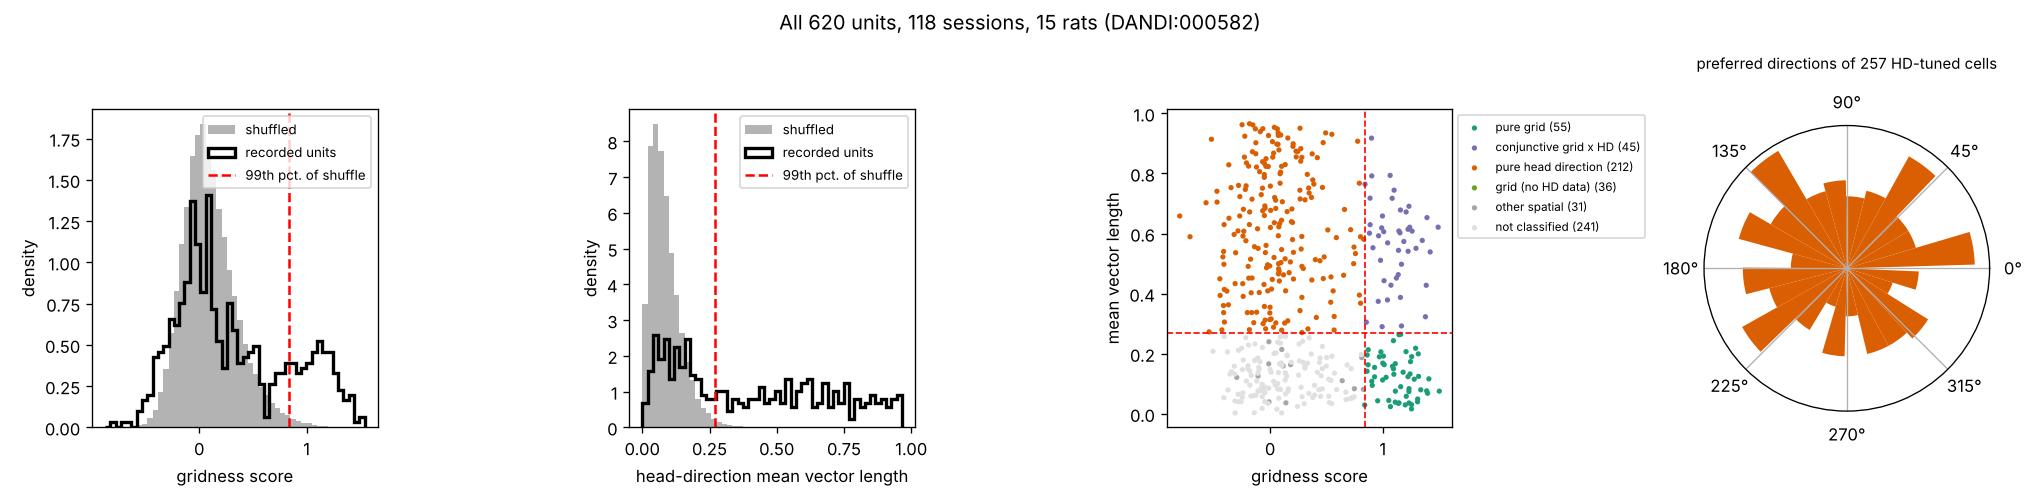

In [9]:
display(Image("figures/03_population_metrics.png"))

Both gridness and head-direction MVL of the recorded units have long right tails that the shuffled data
do not have. Grid cells and head-direction cells form separate clusters in the gridness vs MVL plane,
with conjunctive cells where they overlap. Preferred directions of HD cells cover all directions, so
the population can represent any heading.

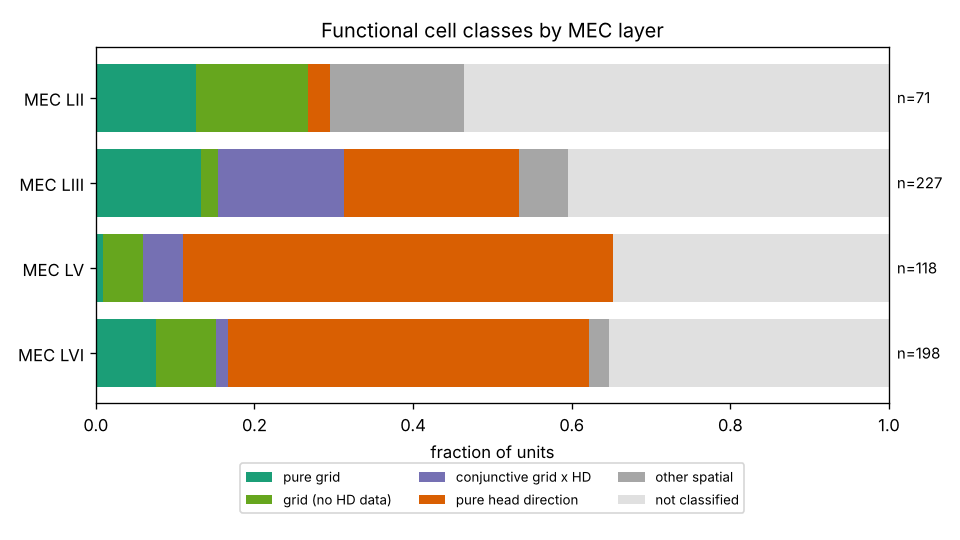

,conjunctive grid x HD,grid (no HD data),not classified,other spatial,pure grid,pure head direction,total
layer,,,,,,,
MEC LII,0,10,38,12,9,2,71
MEC LIII,36,5,92,14,30,50,227
MEC LV,6,6,41,0,1,64,118
MEC LVI,3,15,70,5,15,90,198
unknown,0,0,0,0,0,6,6


In [10]:
display(Image("figures/04_classes_by_layer.png"))
pd.read_csv("results/class_by_layer.csv", index_col=0)

The layer distribution matches Sargolini et al. (2006). Pure grid cells are most common in layers II
and III. Conjunctive grid x HD cells are concentrated in layer III. Pure head-direction cells dominate
layers V and VI. Many layer II sessions lack the second LED, so their units cannot be tested for
head-direction tuning (shown as "grid (no HD data)").

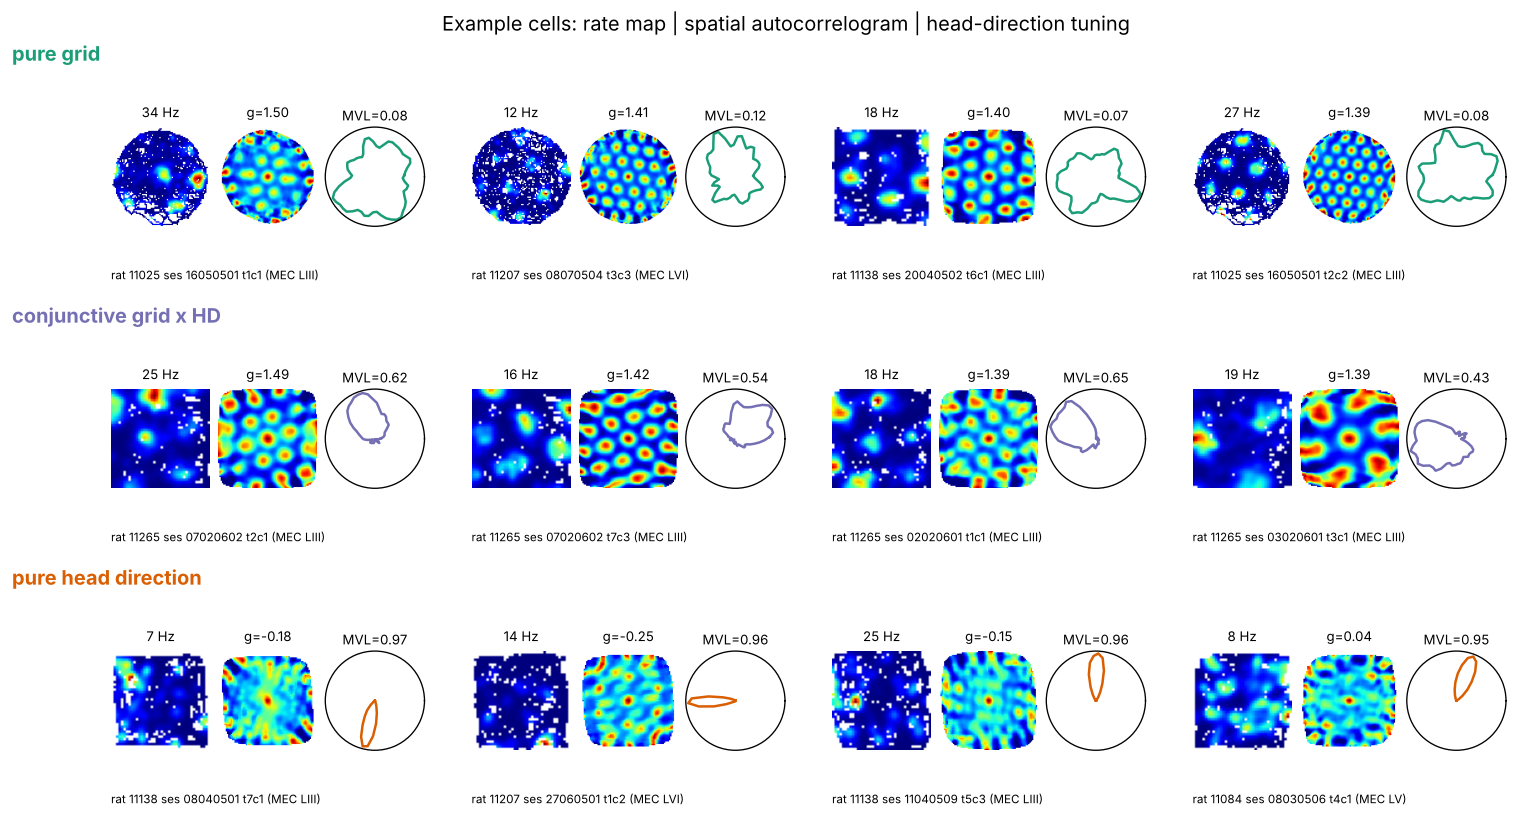

In [11]:
display(Image("figures/05_example_cells.png"))

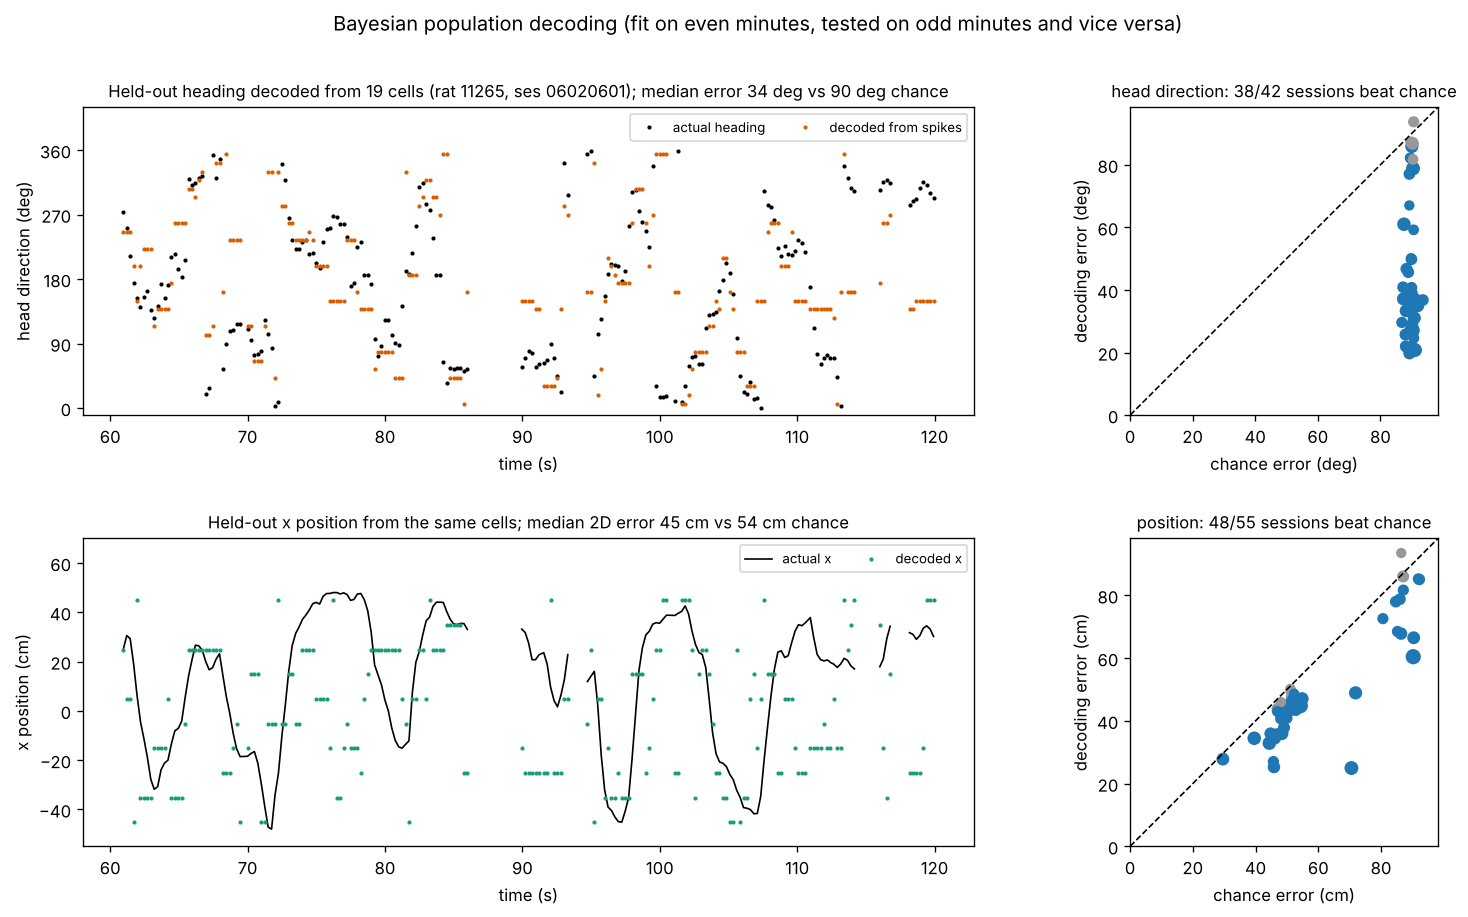

units: 620, sessions: 118, rats: 15
thresholds (99th pct pooled shuffle): {'spatial_info': np.float64(1.1812650941224425), 'gridness': np.float64(0.8387207929312406), 'mvl': np.float64(0.26958729293503764)}

cls       conjunctive grid x HD  grid (no HD data)  not classified  other spatial  pure grid  pure head direction  total
layer                                                                                                                   
MEC LII                       0                 10              38             12          9                    2     71
MEC LIII                     36                  5              92             14         30                   50    227
MEC LV                        6                  6              41              0          1                   64    118
MEC LVI                       3                 15              70              5         15                   90    198
unknown                       0                  0               0

In [12]:
display(Image("figures/06_decoding.png"))
print(open("results/summary.txt").read())

## Interpretation

**Which way am I facing?** Over half of the MEC units with heading data are tuned to head direction, and
their preferred directions cover the full circle. From 5 to 19 simultaneously recorded cells, heading
on held-out data is decoded with a median error of about 38 degrees (chance about 90 degrees), and the
decoder beats chance in 38 of 42 sessions.

**Where am I?** About a fifth of units are grid cells, with firing fields on a hexagonal lattice. The
lattice is periodic, so a few cells from one grid module can tell apart nearby locations but leave
distant locations ambiguous. That explains why position decoding beats chance in most sessions
(48 of 55) but is coarse in absolute terms (median 44 cm vs 51 cm chance). An unambiguous position
code is thought to need grid cells from several modules with different spacings, plus input from
hippocampal place cells, which these recordings do not include.

**How could the two be combined?** Conjunctive grid x HD cells, concentrated in layer III, fire only at
grid locations and only for one heading. This is the type of signal a path-integration circuit needs to
shift its position estimate in the direction of travel. The data are consistent with the MEC holding a
self-motion-based map in which heading and position signals are combined, as proposed in the original
study.

**Caveats.** Recording sessions are short (10 to 20 minutes) and contain few units. Unit counts per
layer are unequal. Head direction is defined up to an unknown constant offset. Arena size in 22 sessions
was inferred from tracking data because the metadata state a 1 m box for all sessions.